In [ ]:
import numpy as np
import pandas as pd

In [ ]:
a=pd.read_csv('/content/Unified_Leads.csv')
print(a)

                   Name  contact_number                    Contact_email  \
0          Anjali Singh      9931980478      anjali.singh878@hotmail.com   
1            Kiran Bose      6474315136        kiran.bose601@example.com   
2      Karthik Malhotra      6753707898  karthik.malhotra329@example.com   
3         Anjali Sharma      9439163624      anjali.sharma85@example.com   
4          Sneha Kapoor      9878269840         sneha.kapoor46@gmail.com   
...                 ...             ...                              ...   
27370       Rohit Reddy      6992973331       rohit.reddy220@hotmail.com   
27371      Kiran Shetty      9410734029      kiran.shetty925@outlook.com   
27372       Neha Shetty      9508547875         neha.shetty6@example.com   
27373      Nikhil Yadav      7870690595      nikhil.yadav620@outlook.com   
27374      Nikhil Reddy      8750283113        nikhil.reddy172@gmail.com   

          creation_date first_call_attempt               lead_status  \
0      03-02-20

In [ ]:
print(a.shape)
print(a.size)
print(a.isna().sum())

(27375, 15)
410625
Name                      0
contact_number            0
Contact_email             0
creation_date             0
first_call_attempt     6729
lead_status               0
lead_stage                0
lead_tag              11416
assigned_to               0
last_call_date         6729
last_call_time         6729
references            27375
campaign_name             0
source_type               0
source_name               0
dtype: int64


In [ ]:
a1=a.drop(['Name', 'contact_number', 'Contact_email','creation_date', 'first_call_attempt', 'last_call_date',
           'last_call_time', 'references'],axis=1)
a1

,lead_status,lead_stage,lead_tag,assigned_to,campaign_name,source_type,source_name
0,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
...,...,...,...,...,...,...,...
27370,CLOSED,LOST,not-interested,Riswana,Business Accounting,INSTAGRAM,INSTAGRAM
27371,CLOSED,LOST,lost-to-competition,Anshad,Business Accounting,INSTAGRAM,INSTAGRAM
27372,CLOSED,CONVERTED,NaN,Anshad,Business Accounting,INSTAGRAM,INSTAGRAM
27373,RESCHEDULED BY EXECUTIVE,Follow Up Required,cold,Anshad,Business Accounting,INSTAGRAM,INSTAGRAM


In [ ]:
a1['lead_tag']=a1['lead_tag'].fillna('Do Not Know')
a['lead_tag']=a['lead_tag'].fillna('Do Not Know')
a1

,lead_status,lead_stage,lead_tag,assigned_to,campaign_name,source_type,source_name
0,PENDING WITH EXECUTIVE,Prospect,Do Not Know,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,PENDING WITH EXECUTIVE,Prospect,Do Not Know,Anshad,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,PENDING WITH EXECUTIVE,Prospect,Do Not Know,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,PENDING WITH EXECUTIVE,Prospect,Do Not Know,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,PENDING WITH EXECUTIVE,Prospect,Do Not Know,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
...,...,...,...,...,...,...,...
27370,CLOSED,LOST,not-interested,Riswana,Business Accounting,INSTAGRAM,INSTAGRAM
27371,CLOSED,LOST,lost-to-competition,Anshad,Business Accounting,INSTAGRAM,INSTAGRAM
27372,CLOSED,CONVERTED,Do Not Know,Anshad,Business Accounting,INSTAGRAM,INSTAGRAM
27373,RESCHEDULED BY EXECUTIVE,Follow Up Required,cold,Anshad,Business Accounting,INSTAGRAM,INSTAGRAM


In [ ]:
from sklearn.preprocessing import LabelEncoder
y = (a1['lead_stage'] == 'CONVERTED').astype(int)
x = a1.drop(columns=['lead_stage', 'lead_status'])
x_encoded = x.copy()
for col in x_encoded.columns:
    le = LabelEncoder()
    x_encoded[col] = le.fit_transform(x_encoded[col].astype(str))
x_encoded

,lead_tag,assigned_to,campaign_name,source_type,source_name
0,0,4,5,2,10
1,0,4,5,0,9
2,0,4,5,2,10
3,0,4,5,2,10
4,0,4,5,2,10
...,...,...,...,...,...
27370,6,16,2,2,10
27371,5,4,2,2,10
27372,0,4,2,2,10
27373,3,4,2,2,10


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x_encoded,y,test_size=0.30,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
sc.fit(x_train)
x_train=sc.transform(x_train)
x_test=sc.transform(x_test)
x_train

array([[ 1.07623992,  0.28117468, -0.71201776,  0.24988804, -0.52505353],
       [-1.091854  ,  0.88059274, -0.71201776,  0.24988804, -0.52505353],
       [-1.091854  , -0.61795241,  1.28692168,  1.76088665,  0.25960406],
       ...,
       [-1.091854  ,  0.13132017, -0.55825318,  0.24988804, -0.52505353],
       [-0.00780704, -0.76780692, -0.71201776,  0.24988804, -0.52505353],
       [ 1.07623992, -0.31824338,  0.36433425,  0.24988804, -0.52505353]])

In [ ]:
from sklearn.ensemble import RandomForestClassifier
r=RandomForestClassifier(n_estimators=100,random_state=42)
r.fit(x_train,y_train)
y_pred=r.predict(x_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score,roc_auc_score,classification_report
cm=confusion_matrix(y_test,y_pred)
print(cm)
acc=accuracy_score(y_test,y_pred)
print('*****************************')
print("The accuracy score is:",acc)
print('*****************************')
auc=roc_auc_score(y_test,y_pred)
print("The auc score is:",auc)
print('*****************************')
print("The classification report")
print(classification_report(y_pred,y_test))

[[7920   52]
 [  72  169]]
*****************************
The accuracy score is: 0.9849019846584682
*****************************
The auc score is: 0.847360991686671
*****************************
The classification report
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      7992
           1       0.70      0.76      0.73       221

    accuracy                           0.98      8213
   macro avg       0.85      0.88      0.86      8213
weighted avg       0.99      0.98      0.99      8213



In [ ]:
x_all_scaled = sc.transform(x_encoded)
a['conversion_probability'] = r.predict_proba(x_all_scaled)[:, 1]
followup_leads = a[a['lead_stage'].isin(['Follow Up Required','Prospect'])]
priority_list = followup_leads[
    ['Name', 'contact_number', 'assigned_to', 'campaign_name', 'lead_tag', 'conversion_probability']
].sort_values(by='conversion_probability', ascending=False)

print("\n--- HIGH-PRIORITY LEADS TO FOLLOW UP FIRST ---")
priority_list


--- HIGH-PRIORITY LEADS TO FOLLOW UP FIRST ---


,Name,contact_number,assigned_to,campaign_name,lead_tag,conversion_probability
14128,Vikram Reddy,7148920312,Anshad,Business Accounting,Do Not Know,0.838115
24539,Meera Kapoor,7244264365,Anshad,Business Accounting,Do Not Know,0.838115
14810,Varun Chopra,7692810302,Anshad,Business Accounting,Do Not Know,0.838115
23259,Aditya Kulkarni,9541542869,Anshad,Business Accounting,Do Not Know,0.838115
12504,Rahul Yadav,9286252876,Anshad,Business Accounting,Do Not Know,0.838115
...,...,...,...,...,...,...
13194,Aisha Sharma,6405560934,Anshad,Digital Marketing Knovista,cold,0.000000
13195,Aditya Pillai,7006432729,Anshad,BA NEW 18-08-2025,cold,0.000000
13198,Meera Bhat,8544187477,Anshad,Digital Marketing Knovista,cold,0.000000
13203,Aditya Das,9435172737,Anshad,BA NEW 18-08-2025,cold,0.000000


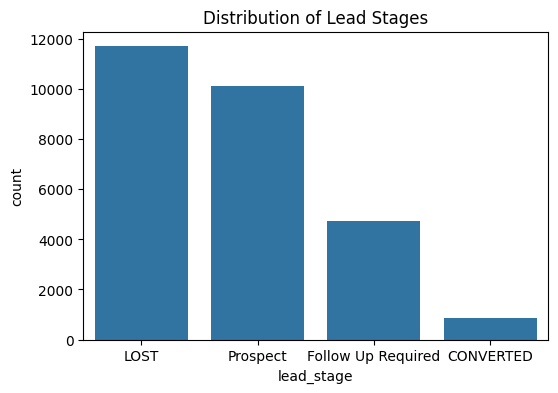

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.countplot(x='lead_stage', data=a, order=a['lead_stage'].value_counts().index)
plt.title("Distribution of Lead Stages")
plt.show()

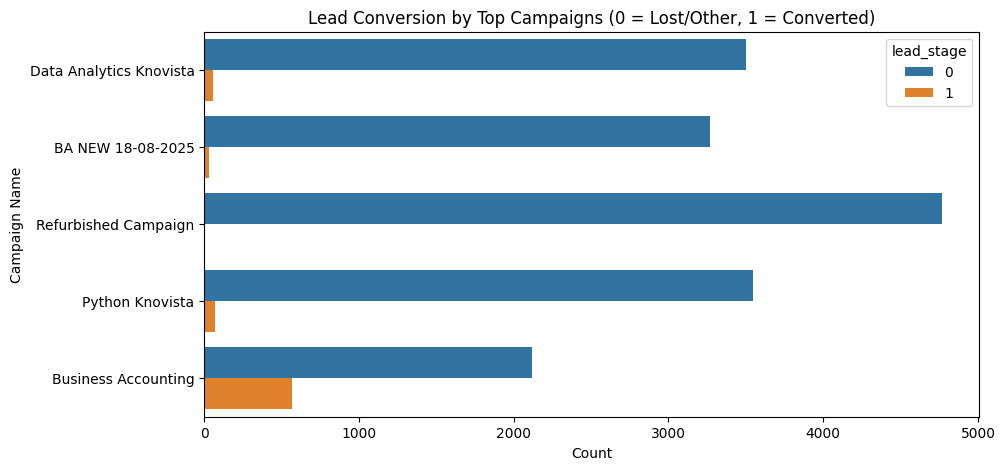

In [ ]:
top_campaigns = a['campaign_name'].value_counts().head(5).index
plt.figure(figsize=(10, 5))
sns.countplot(y='campaign_name', hue=y, data=a[a['campaign_name'].isin(top_campaigns)])
plt.title("Lead Conversion by Top Campaigns (0 = Lost/Other, 1 = Converted)")
plt.xlabel("Count")
plt.ylabel("Campaign Name")
plt.show()

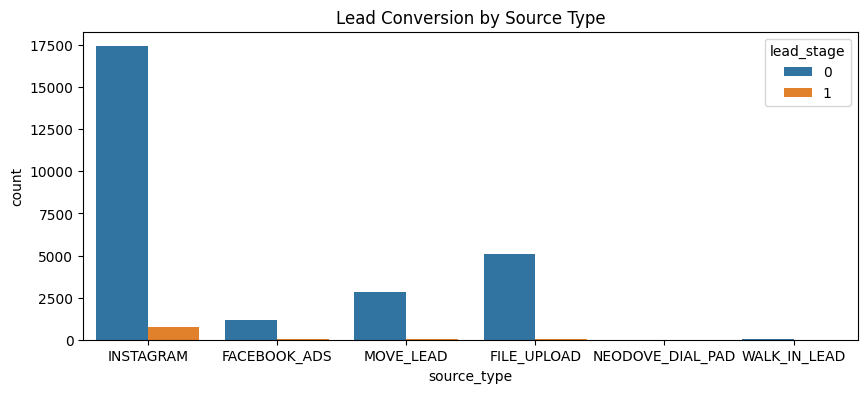

In [ ]:
plt.figure(figsize=(10, 4))
sns.countplot(x='source_type', hue=y, data=a)
plt.title("Lead Conversion by Source Type")
plt.show()